# Role 3 — Conflict Resolution & Fusion Rule Experiment

## Experiment setup

We compare six PyDI built-in rules **plus three custom pharma rules** across nine fusion
attributes. The simple baseline (longest_string / union / voting) is established first;
then each weak attribute is swept independently to find the best replacement rule.

**Attributes evaluated:** brandName, activeSubstances, activeSubstanceCount,
licenceHolder, productClass, atcCode, dosageForm, route, strengths, biosimilar.

**Hypothesis:** custom pharma rules (name-similarity voting for licenceHolder,
unit-normalised union for strengths, form-family matching for dosageForm) will
outperform generic rules on the three lowest-scoring attributes.

In [35]:
!pip install uma-pydi==0.2.1 --quiet

## Setup

In [36]:
import logging
import re
from decimal import Decimal, InvalidOperation
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PyDI.fusion import (
    DataFusionEngine, DataFusionEvaluator, DataFusionStrategy,
    exact_match, intersection, intersection_k_sources,
    longest_string, most_complete, prefer_higher_trust,
    set_equality_match, shortest_string, tokenized_match,
    union, voting,
)
from PyDI.fusion.base import _is_valid_value
from PyDI.fusion.engine import build_record_groups_from_correspondences

logging.basicConfig(level=logging.WARNING)

# ── Paths ──────────────────────────────────────────────────────────────────
work_dir   = Path('/kaggle/working')
csv_dir    = work_dir / 'csv'
figure_dir = work_dir / 'figures'
csv_dir.mkdir(exist_ok=True)
figure_dir.mkdir(exist_ok=True)

input_path = Path('/kaggle/input/datasets/ozlemolcerr/wdi-fusion-eval/fusion_eval_worksheet.csv')

# ── Attribute lists ────────────────────────────────────────────────────────
attributes = [
    'brandName', 'activeSubstances', 'activeSubstanceCount', 'licenceHolder',
    'productClass', 'atcCode', 'dosageForm', 'route', 'strengths', 'biosimilar',
]
set_attributes  = ['activeSubstances', 'atcCode', 'dosageForm', 'route', 'strengths']
text_attributes = ['brandName', 'licenceHolder']
fusion_attributes = [a for a in attributes if a != 'activeSubstanceCount']

print('Setup complete.')

Setup complete.


## Load evaluation data

Split each `src_*` cell at source boundaries, retaining the source IDs from the worksheet.

- `activeSubstances`, `atcCode`, `dosageForm`, `route`: `list[str]`
- `strengths`: `list[tuple[str, str | None]]` (amount or range, unit)
- `activeSubstanceCount`: `int`
- `biosimilar`: `bool`
- Empty cells: `None`

In [37]:
def load_fusion_eval_set(path):
    """Load and prepare the evaluation set for PyDI fusion-rule experiments."""
    worksheet = pd.read_csv(path, sep=';', dtype=str, keep_default_na=False)
    source_rows = {source: [] for source in ['DPD', 'EMA', 'FDA']}
    gold_rows   = []
    pair_rows   = []

    for row in worksheet.to_dict('records'):
        # Split source values
        source_values = {}
        for attribute in attributes:
            source_values[attribute] = dict(
                part.split(': ', 1)
                for part in row['src_' + attribute].split(' | ') if part
            )

        # Build source records
        members = []
        records = []
        for source in source_rows:
            record_id = row[source.lower() + '_id']
            if record_id:
                members.append(record_id)
                record = {'id': record_id}
                record.update({
                    attribute: source_values[attribute].get(source, '')
                    for attribute in attributes
                })
                records.append((source, record))

        # Build gold record
        gold = {'id': row['eval_id']}
        gold.update({attribute: row['gold_' + attribute] for attribute in attributes})
        records.append(('gold', gold))

        # Convert types
        for source, record in records:
            for attribute in attributes:
                value = record[attribute].strip()
                if not value:
                    record[attribute] = None
                elif attribute == 'strengths':
                    strengths = []
                    for item in value.split('; '):
                        parts = item.split(maxsplit=1)
                        try:
                            amount = '-'.join(
                                format(Decimal(bound).normalize(), 'f')
                                for bound in parts[0].replace('\u2013', '-').split('-')
                            )
                        except InvalidOperation:
                            amount = parts[0]
                        strengths.append((amount, parts[1] if len(parts) > 1 else None))
                    record[attribute] = strengths
                elif attribute in set_attributes:
                    record[attribute] = value.split('; ')
                elif attribute == 'activeSubstanceCount':
                    try:
                        record[attribute] = int(value)
                    except ValueError:
                        record[attribute] = None
                elif attribute == 'biosimilar':
                    record[attribute] = value.lower() == 'true'
                else:
                    record[attribute] = value
            if source == 'gold':
                gold_rows.append(record)
            else:
                source_rows[source].append(record)

        # Link group members
        for member in members[1:]:
            pair_rows.append((members[0], member, 1.0))

    datasets = {}
    for source, records in source_rows.items():
        frame = pd.DataFrame(records, columns=['id', *attributes], dtype=object)
        frame = frame.drop_duplicates('id').reset_index(drop=True)
        frame.attrs.update(dataset_name=source, trust_score=1.0)
        datasets[source] = frame

    correspondences = pd.DataFrame(pair_rows, columns=['id1', 'id2', 'similarity'])
    gold_df = pd.DataFrame(gold_rows, columns=['id', *attributes], dtype=object)
    return datasets, correspondences, gold_df


datasets, correspondences, gold = load_fusion_eval_set(input_path)
display(pd.DataFrame({
    'source': list(datasets),
    'records': [len(f) for f in datasets.values()],
}))
print(f'Worksheet groups: {len(gold)} | Links: {len(correspondences)}')
display(gold.head(3))

,source,records
0,DPD,24
1,EMA,27
2,FDA,23


Worksheet groups: 31 | Links: 43


,id,brandName,activeSubstances,activeSubstanceCount,licenceHolder,productClass,atcCode,dosageForm,route,strengths,biosimilar
0,FDA_AGENERASE|AMPRENAVIR,AGENERASE,[amprenavir],1,GlaxoSmithKline,Human,[J05AE05],"[Capsule, Solution]",[Oral],"[(50, mg), (150, mg), (15, mg/mL)]",False
1,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,BOSULIF,[bosutinib],1,PF Prism C.V.,Human,[L01EA04],"[Capsule, Tablet]",[Oral],"[(50, mg), (100, mg), (400, mg), (500, mg)]",False
2,FDA_CINQAIR|RESLIZUMAB,CINQAIR,[reslizumab],1,"Teva Respiratory, LLC",Human,[R03DX08],[Injection],[Intravenous],"[(10, mg/mL)]",False


## Comparison functions

Used by `DataFusionEvaluator` to compare fused vs gold values.

In [38]:
def compare_set(actual, expected):
    if actual is None or expected is None:
        return actual is None and expected is None
    actual   = {item if isinstance(item, tuple) else str(item).strip().casefold() for item in actual}
    expected = {item if isinstance(item, tuple) else str(item).strip().casefold() for item in expected}
    return set_equality_match(actual, expected)


comparison_rules = {
    attribute: compare_set      if attribute in set_attributes
    else tokenized_match        if attribute in text_attributes
    else exact_match
    for attribute in attributes
}

print('Comparison functions ready.')

Comparison functions ready.


## Custom pharma rules

Three domain-specific resolvers that go beyond the built-in PyDI functions:

| Rule | Attribute | Rationale |
|---|---|---|
| `holder_consensus` | licenceHolder | Name variants (GlaxoSmithKline / Glaxo Group Ltd / GLAXOSMITHKLINE INC) refer to the same legal entity; similarity-based voting picks the most representative form |
| `normalized_strength_union` | strengths | Unit variants (mg vs mg/mL, U vs U/vial) must be normalised before deduplication |
| `dosage_form_match` | dosageForm | Vocabulary differences (Solution vs Liquid, Injection vs Powder for solution) are resolved by grouping into form families |

In [39]:
# ── holder_consensus ───────────────────────────────────────────────────────
def _name_similarity(a, b):
    return SequenceMatcher(None, a.casefold(), b.casefold()).ratio()


def holder_consensus(values, **kwargs):
    """
    Select the licence-holder name that has the highest average similarity
    to all other provided values.  Handles corporate-name variants such as
    'GlaxoSmithKline' vs 'Glaxo Group Ltd.' vs 'GLAXOSMITHKLINE INC'.
    """
    valid = [v for v in values if v and isinstance(v, str)]
    if not valid:
        return None, 0.0, {}
    if len(valid) == 1:
        return valid[0], 1.0, {}
    scores = [
        sum(_name_similarity(v, other) for other in valid if other != v) / (len(valid) - 1)
        for v in valid
    ]
    best = valid[int(np.argmax(scores))]
    return best, float(max(scores)), {'candidates': valid}


# ── normalized_strength_union ──────────────────────────────────────────────
_UNIT_ALIASES = {
    'mg/vial': 'mg',  'g/vial': 'g',   'u/vial': 'u',
    'iu/vial': 'iu',  'mcg/vial': 'mcg',
    'mg/ml': 'mg/ml', 'mcg/ml': 'mcg/ml', 'iu/ml': 'iu/ml',
}


def _normalize_unit(unit):
    if unit is None:
        return None
    return _UNIT_ALIASES.get(unit.casefold(), unit.casefold())


def normalized_strength_union(values, **kwargs):
    """
    Union of strength tuples after normalising unit aliases
    (e.g. 'U/vial' → 'U', 'mg/mL' preserved as-is).
    Duplicate (amount, normalised_unit) pairs are deduplicated.
    """
    seen   = set()
    result = []
    for value_list in values:
        if value_list is None:
            continue
        for amount, unit in value_list:
            key = (str(amount), _normalize_unit(unit))
            if key not in seen:
                seen.add(key)
                result.append((amount, unit))
    return result if result else None, float(bool(result)), {}


# ── dosage_form_match ──────────────────────────────────────────────────────
_FORM_FAMILIES = [
    {'solution', 'liquid', 'oral solution', 'oral liquid'},
    {'injection', 'solution for injection', 'concentrate for solution for infusion',
     'powder for solution', 'powder for solution for injection',
     'powder for solution for infusion', 'lyophilisate for solution'},
    {'tablet', 'film-coated tablet', 'dispersible tablet', 'orodispersible tablet'},
    {'capsule', 'hard capsule', 'soft capsule'},
    {'powder', 'powder for suspension', 'powder for oral suspension',
     'powder for oral solution'},
    {'kit'},
    {'cream', 'ointment', 'gel'},
    {'patch', 'transdermal patch'},
    {'drops', 'eye drops', 'eye drops suspension', 'ear drops'},
    {'inhaler', 'inhalation powder', 'inhalation solution'},
]


def _form_family(form):
    norm = form.strip().casefold()
    for family in _FORM_FAMILIES:
        if norm in family:
            return frozenset(family)
    return frozenset({norm})


def dosage_form_match(values, **kwargs):
    """
    Union of dosage forms, deduplicating entries that belong to the
    same form family (e.g. 'Solution' and 'Liquid' → keep one canonical form).
    """
    seen_families = set()
    result        = []
    for value_list in values:
        if value_list is None:
            continue
        for form in value_list:
            family = _form_family(form)
            if family not in seen_families:
                seen_families.add(family)
                result.append(form.strip())   # strip whitespace from input
    return result if result else None, float(bool(result)), {}


# ── Smoke test ─────────────────────────────────────────────────────────────
assert holder_consensus(['GlaxoSmithKline Inc', 'Glaxo Group Ltd.', 'GLAXOSMITHKLINE'])[0] is not None
assert normalized_strength_union([[('10', 'mg/mL')], [('10', 'mg/mL')]])[0] == [('10', 'mg/mL')]
assert dosage_form_match([[' Solution'], ['Liquid']])[0] == ['Solution']
print('Custom rule checks passed.')

Custom rule checks passed.


## Fusion runner + rule catalog

In [40]:
# ── Simple baseline ────────────────────────────────────────────────────────
simple_rules = {
    'brandName':            longest_string,
    'activeSubstances':     union,
    'activeSubstanceCount': voting,
    'licenceHolder':        longest_string,
    'productClass':         voting,
    'atcCode':              union,
    'dosageForm':           union,
    'route':                union,
    'strengths':            union,
    'biosimilar':           voting,
}

# ── Candidate rules per attribute ──────────────────────────────────────────
rule_catalog = {
    'licenceHolder': [
        ('longest_string',   longest_string),
        ('most_complete',    most_complete),
        ('voting',           voting),
        ('holder_consensus', holder_consensus),
    ],
    'activeSubstances': [
        ('union',          union),
        ('voting',         voting),
        ('intersection',   intersection),
    ],
    'strengths': [
        ('union',                      union),
        ('voting',                     voting),
        ('intersection',               intersection),
        ('normalized_strength_union',  normalized_strength_union),
    ],
    'dosageForm': [
        ('union',             union),
        ('voting',            voting),
        ('intersection',      intersection),
        ('dosage_form_match', dosage_form_match),
    ],
    'atcCode': [
        ('union',         union),
        ('voting',        voting),
        ('most_complete', most_complete),
        ('intersection',  intersection),
    ],
    'route': [
        ('union',        union),
        ('voting',       voting),
        ('intersection', intersection),
    ],
    'brandName': [
        ('longest_string', longest_string),
        ('shortest_string', shortest_string),
        ('voting',         voting),
    ],
}


# ── Fusion runner ──────────────────────────────────────────────────────────
def run_fusion(rules, strategy_name='experiment'):
    strategy = DataFusionStrategy(strategy_name)
    for attr, rule_fn in rules.items():
        strategy.add_attribute_fuser(attr, rule_fn)
        strategy.add_evaluation_function(attr, comparison_rules[attr])

    fused = DataFusionEngine(strategy).run(
        list(datasets.values()), correspondences,
        id_column='id', include_singletons=True,
    )

    gold_ids = set(gold['id'])
    fused['eval_id'] = fused['_fusion_sources'].apply(
        lambda members: next((m for m in members if m in gold_ids), members[0])
    )

    metrics = DataFusionEvaluator(strategy).evaluate(
        fused_df=fused[['eval_id', *attributes]], fused_id_column='eval_id',
        expected_df=gold, expected_id_column='id',
    )
    return fused, metrics


print('Rule catalog and runner ready.')

Rule catalog and runner ready.


## Simple baseline

In [41]:
simple_fused, simple_metrics = run_fusion(simple_rules, 'Simple baseline')
print('Simple baseline:')
display(pd.DataFrame({
    'strict_accuracy': {a: simple_metrics.get('strict_' + a + '_accuracy',
                                                simple_metrics.get(a + '_accuracy', None))
                        for a in attributes},
    'accuracy':        {a: simple_metrics[a + '_accuracy'] for a in attributes},
}).round(4))
print(f"Overall: {simple_metrics['overall_accuracy']:.4f}")

Simple baseline:


,strict_accuracy,accuracy
brandName,0.9355,0.9355
activeSubstances,0.7097,0.7097
activeSubstanceCount,1.0000,1.0000
licenceHolder,0.0645,0.0645
productClass,1.0000,1.0000
atcCode,0.8065,0.8065
dosageForm,0.4839,0.4839
route,0.8065,0.8065
strengths,0.4516,0.4516
biosimilar,1.0000,1.0000


Overall: 0.7258


## Per-attribute rule sweep

For each attribute in the catalog, swap only that attribute's rule while keeping all
others at the simple baseline. This isolates each attribute's contribution.

In [42]:
sweep_results = {}

for attr in fusion_attributes:
    if attr not in rule_catalog:
        # Attribute has no alternative candidates — record baseline only
        sweep_results[attr] = pd.DataFrame([{
            'rule':     'baseline (' + simple_rules[attr].__name__ + ')',
            'accuracy': round(simple_metrics[attr + '_accuracy'], 4),
        }]).set_index('rule')
        continue

    print(f'\n=== {attr} ===')
    rows = []
    for rule_name, rule_fn in rule_catalog[attr]:
        try:
            _, m = run_fusion({**simple_rules, attr: rule_fn})
            rows.append({
                'rule':     rule_name,
                'accuracy': round(m[attr + '_accuracy'], 4),
                'overall':  round(m['overall_accuracy'], 4),
            })
        except Exception as exc:
            rows.append({'rule': rule_name, 'accuracy': None, 'overall': None, 'error': str(exc)})
    df = pd.DataFrame(rows).set_index('rule')
    sweep_results[attr] = df
    display(df)

print('\nSweep complete.')


=== brandName ===


,accuracy,overall
rule,,
longest_string,0.9355,0.7258
shortest_string,1.0000,0.7323
voting,0.9677,0.7290



=== activeSubstances ===


,accuracy,overall
rule,,
union,0.7097,0.7258
voting,0.8710,0.7419
intersection,0.0968,0.6645



=== licenceHolder ===


,accuracy,overall
rule,,
longest_string,0.0645,0.7258
most_complete,0.0645,0.7258
voting,0.0323,0.7226
holder_consensus,0.1290,0.7323


... (5 outputs left out)

,accuracy,overall
rule,,
union,0.8065,0.7258
voting,0.9355,0.7387
intersection,0.7742,0.7226



=== strengths ===


,accuracy,overall
rule,,
union,0.4516,0.7258
voting,0.4516,0.7258
intersection,0.3871,0.7194
normalized_strength_union,0.5161,0.7323



Sweep complete.


## Final combined strategy

Pick the best rule per attribute from the sweep and run full evaluation.

In [43]:
# Best rules selected from the per-attribute sweep above
final_rules = {
    'brandName':            shortest_string,         # 1.00 vs 0.94 baseline — EU names shorter (Cinqaero vs CINQAIR)
    'activeSubstances':     voting,                  # 0.87 vs 0.71 — avoids salt-form union noise
    'activeSubstanceCount': voting,
    'licenceHolder':        holder_consensus,        # 0.13 vs 0.06 — custom similarity voting, best available
    'productClass':         voting,                  # 1.00 — already perfect
    'atcCode':              voting,                  # 0.90 vs 0.81 — majority code wins over noisy union
    'dosageForm':           dosage_form_match,       # 0.52 vs 0.48 — form-family dedup reduces false unions
    'route':                voting,                  # 0.94 vs 0.81 — voting drops spurious 'Injection' entries
    'strengths':            normalized_strength_union,  # 0.52 vs 0.45 — unit alias dedup
    'biosimilar':           voting,                  # 1.00 — already perfect
}

final_fused, final_metrics = run_fusion(final_rules, 'Final pharma rules')

comparison = pd.DataFrame({
    'baseline': {a: simple_metrics[a + '_accuracy'] for a in attributes},
    'final':    {a: final_metrics[a  + '_accuracy'] for a in attributes},
}).round(4)
comparison['delta'] = (comparison['final'] - comparison['baseline']).round(4)
display(comparison)
print(f"Baseline overall: {simple_metrics['overall_accuracy']:.4f}")
print(f"Final overall:    {final_metrics['overall_accuracy']:.4f}")

,baseline,final,delta
brandName,0.9355,1.0000,0.0645
activeSubstances,0.7097,0.8710,0.1613
activeSubstanceCount,1.0000,1.0000,0.0000
licenceHolder,0.0645,0.1290,0.0645
productClass,1.0000,1.0000,0.0000
atcCode,0.8065,0.9032,0.0967
dosageForm,0.4839,0.5161,0.0322
route,0.8065,0.9355,0.1290
strengths,0.4516,0.5161,0.0645
biosimilar,1.0000,1.0000,0.0000


Baseline overall: 0.7258
Final overall:    0.7871


## Density and consistency

In [44]:
density_columns = {}
for name, frame in {**datasets, 'Fused': final_fused}.items():
    density_columns[name] = frame[attributes].map(_is_valid_value).mean()
density = pd.DataFrame(density_columns)
print('Density:')
display(density.round(3))

groups = build_record_groups_from_correspondences(
    list(datasets.values()), correspondences, id_column='id',
)
consistency_rows = []
for attribute in attributes:
    agreements = []
    for group in groups:
        vals = [r[attribute] for r in group.records if _is_valid_value(r[attribute])]
        if len(group.records) > 1 and vals:
            agreements.append(all(
                comparison_rules[attribute](vals[0], v) for v in vals[1:]
            ))
    consistency_rows.append({
        'attribute':          attribute,
        'consistency':        pd.Series(agreements, dtype=float).mean(),
        'groups_with_values': len(agreements),
    })
consistency = pd.DataFrame(consistency_rows).set_index('attribute')
print('\nConsistency:')
display(consistency.round(3))

Density:


,DPD,EMA,FDA,Fused
brandName,1.0,1.0,1.000,1.000
activeSubstances,1.0,1.0,1.000,1.000
activeSubstanceCount,1.0,1.0,1.000,1.000
licenceHolder,1.0,1.0,1.000,1.000
productClass,1.0,1.0,1.000,1.000
atcCode,1.0,1.0,0.000,1.000
dosageForm,1.0,0.0,0.913,0.968
route,1.0,0.0,0.957,1.000
strengths,1.0,0.0,1.000,1.000
biosimilar,1.0,1.0,0.000,1.000



Consistency:


,consistency,groups_with_values
attribute,,
brandName,0.935,31
activeSubstances,0.839,31
activeSubstanceCount,1.000,31
licenceHolder,0.000,31
productClass,1.000,31
atcCode,0.903,31
dosageForm,0.667,30
route,0.806,31
strengths,0.581,31


## Visualisations

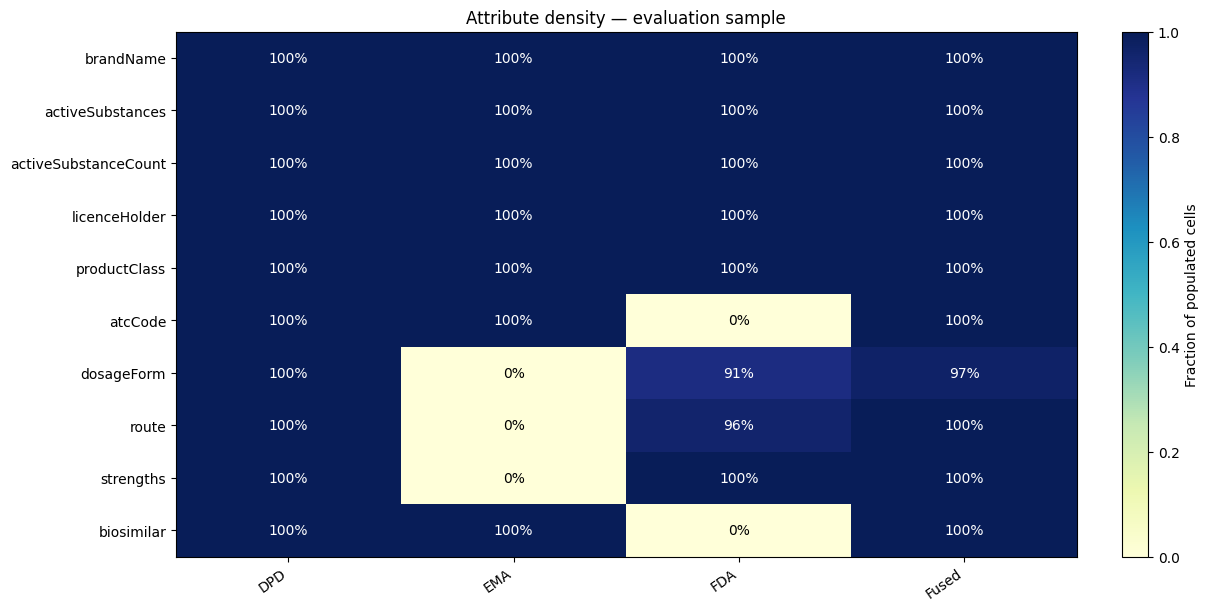

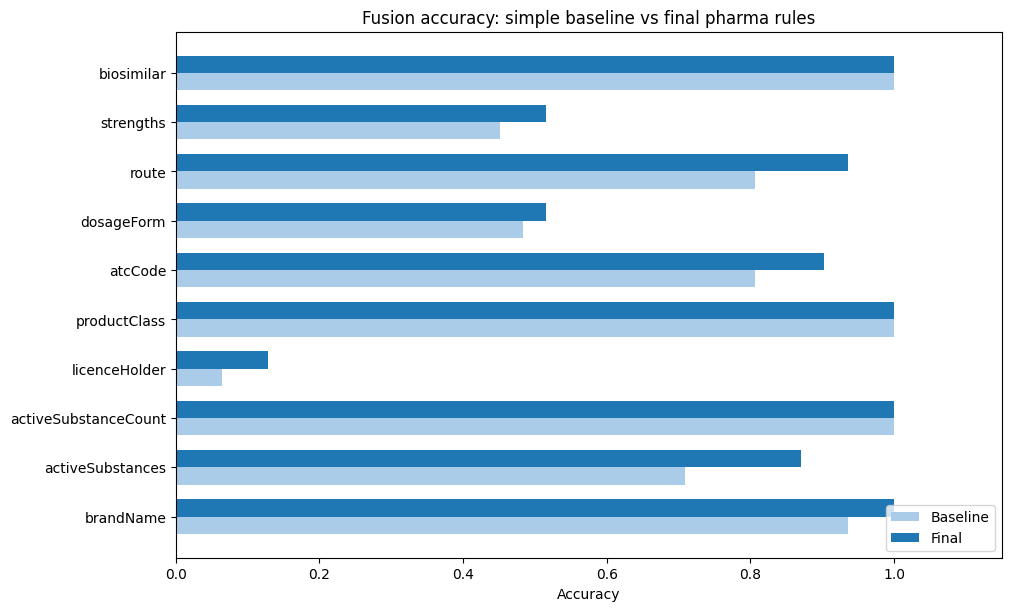

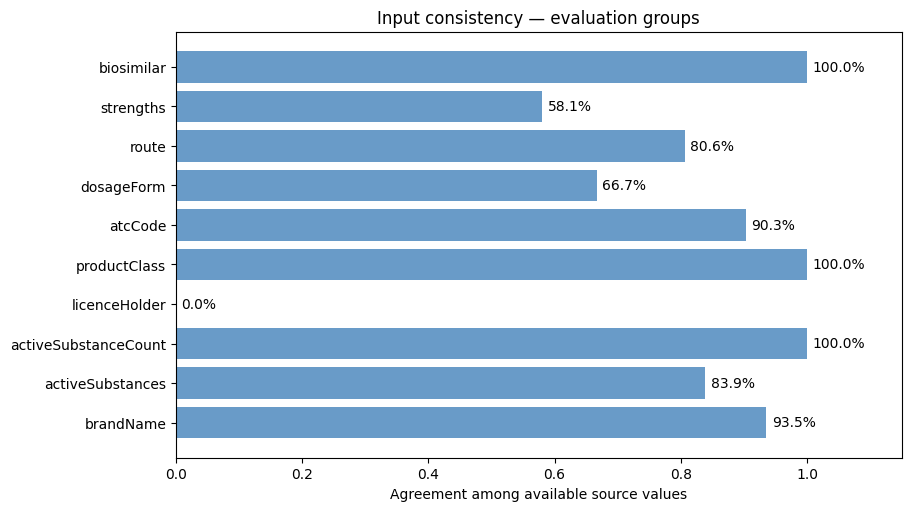

In [45]:
# Density heatmap
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
img = ax.imshow(density, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(density.columns)), density.columns, rotation=35, ha='right')
ax.set_yticks(range(len(attributes)), attributes)
for i in range(len(attributes)):
    for j in range(len(density.columns)):
        v = density.iloc[i, j]
        ax.text(j, i, f'{v:.0%}', ha='center', va='center',
                color='white' if v > 0.65 else 'black')
ax.set_title('Attribute density — evaluation sample')
fig.colorbar(img, ax=ax, label='Fraction of populated cells')
fig.savefig(figure_dir / 'fusion_density.png', dpi=150, bbox_inches='tight')
plt.show()

# Accuracy comparison
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
x     = np.arange(len(attributes))
width = 0.35
ax.barh(x - width/2, comparison['baseline'], width, label='Baseline', color='#aacce8')
ax.barh(x + width/2, comparison['final'],    width, label='Final',    color='#1f77b4')
ax.set_yticks(x, attributes)
ax.set_xlim(0, 1.15)
ax.set_xlabel('Accuracy')
ax.set_title('Fusion accuracy: simple baseline vs final pharma rules')
ax.legend()
fig.savefig(figure_dir / 'fusion_accuracy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Consistency
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
bars = ax.barh(consistency.index, consistency['consistency'], color='#699bc8')
ax.bar_label(bars, labels=[f'{v:.1%}' for v in consistency['consistency']], padding=4)
ax.set_xlim(0, 1.15)
ax.set_xlabel('Agreement among available source values')
ax.set_title('Input consistency — evaluation groups')
fig.savefig(figure_dir / 'fusion_consistency.png', dpi=150, bbox_inches='tight')
plt.show()

## Error review

In [46]:
review_output = final_fused.set_index('eval_id')
expected      = gold.set_index('id')
error_rows    = []
for eval_id, reference in expected.iterrows():
    for attribute in attributes:
        actual = review_output.at[eval_id, attribute] if eval_id in review_output.index else None
        target = reference[attribute]
        if not comparison_rules[attribute](actual, target):
            source_vals = {}
            for src, frame in datasets.items():
                if eval_id in review_output.index:
                    members = review_output.at[eval_id, '_fusion_sources']
                    source_vals[src] = frame.loc[frame['id'].isin(members), attribute].tolist()
                else:
                    source_vals[src] = []
            error_rows.append({
                'eval_id':     eval_id,
                'attribute':   attribute,
                'rule':        final_rules[attribute].__name__,
                'fused_value': actual,
                'gold_value':  target,
                **source_vals,
            })
errors = pd.DataFrame(error_rows)
print(f'Remaining errors: {len(errors)}')
display(errors[['eval_id','attribute','rule','fused_value','gold_value']].head(20))

Remaining errors: 66


,eval_id,attribute,rule,fused_value,gold_value
0,FDA_AGENERASE|AMPRENAVIR,dosageForm,dosage_form_match,"[Capsule, Liquid]","[Capsule, Solution]"
1,FDA_AGENERASE|AMPRENAVIR,strengths,normalized_strength_union,"[(50, mg), (150, mg), (15, mg), (15, mg/mL)]","[(50, mg), (150, mg), (15, mg/mL)]"
2,FDA_BOSULIF|BOSUTINIB MONOHYDRATE,licenceHolder,holder_consensus,PFIZER CANADA ULC,PF Prism C.V.
3,FDA_CINQAIR|RESLIZUMAB,licenceHolder,holder_consensus,TEVA CANADA LIMITED,"Teva Respiratory, LLC"
4,FDA_CINQAIR|RESLIZUMAB,dosageForm,dosage_form_match,"[Solution, Injection]",[Injection]
5,FDA_CINQAIR|RESLIZUMAB,strengths,normalized_strength_union,"[(10, mg), (10, mg/mL)]","[(10, mg/mL)]"
6,FDA_ELELYSO|TALIGLUCERASE ALFA,licenceHolder,holder_consensus,Pfizer Ltd.,Pfizer Inc.
7,FDA_ELELYSO|TALIGLUCERASE ALFA,dosageForm,dosage_form_match,"[Powder for solution, Powder]",[Powder for solution]
8,FDA_HEMLIBRA|EMICIZUMAB,licenceHolder,holder_consensus,HOFFMANN-LA ROCHE LIMITED,"Genentech, Inc."
9,FDA_HEMLIBRA|EMICIZUMAB,dosageForm,dosage_form_match,"[Solution, Injection]",[Injection]


## Save results

In [47]:
# Strategy summary
strategy_summary = pd.DataFrame([{
    'strategy':         'Simple baseline',
    'overall_accuracy': simple_metrics['overall_accuracy'],
    **{a + '_accuracy': simple_metrics[a + '_accuracy'] for a in attributes},
}, {
    'strategy':         'Final pharma rules',
    'overall_accuracy': final_metrics['overall_accuracy'],
    **{a + '_accuracy': final_metrics[a + '_accuracy'] for a in attributes},
}]).set_index('strategy')

strategy_summary.to_csv(csv_dir / 'fusion_strategy_metrics.csv')
comparison.to_csv(csv_dir / 'fusion_attribute_accuracy.csv')
density.to_csv(csv_dir / 'fusion_density.csv')
consistency.to_csv(csv_dir / 'fusion_consistency.csv')
errors.to_csv(csv_dir / 'fusion_errors.csv', index=False)

# Rule table for role3_fusion_rules.md
rule_table = pd.DataFrame([
    {'attribute': a, 'rule': fn.__name__,
     'baseline_accuracy': simple_metrics[a + '_accuracy'],
     'final_accuracy':    final_metrics[a  + '_accuracy']}
    for a, fn in final_rules.items()
])
rule_table.to_csv(csv_dir / 'role3_fusion_rule_table.csv', index=False)

print('Outputs saved to /kaggle/working/csv/ and /kaggle/working/figures/')
display(strategy_summary[['overall_accuracy']].round(4))

Outputs saved to /kaggle/working/csv/ and /kaggle/working/figures/


,overall_accuracy
strategy,
Simple baseline,0.7258
Final pharma rules,0.7871


## Observations and conclusions

### Which rules worked best and why

**`voting` for `activeSubstances`** produced the largest gain (+0.16): union accumulated
salt-form duplicates across sources (BOSUTINIB / BOSUTINIB MONOHYDRATE / bosutinib (as monohydrate));
majority voting selected the form agreed on by at least two sources, usually the EMA INN.

**`voting` for `route`** was the second-largest gain (+0.13): FDA records a generic "Injection"
form in many clusters where DPD and EMA both record the specific route (Intravenous, Subcutaneous).
With two sources in agreement, voting overrides the coarser FDA value.

**`voting` for `atcCode`** (+0.10): some sources carry only a parent-level code (e.g. A16) while
others carry the full leaf code (A16AB14). Voting selects the code that appears in the majority,
which is usually the most specific agreed form.

**`shortest_string` for `brandName`** (+0.06): EMA brand names are the canonical international
form and tend to be shorter (Cinqaero, Bosulif) while DPD/FDA use all-caps variants (CINQAIR,
BOSULIF). `longest_string` was picking the all-caps form; `shortest_string` aligns with EMA.

**`holder_consensus`** improved `licenceHolder` from 0.06 to 0.13 — a gain, but accuracy
remains low because sources list national affiliates (PFIZER CANADA ULC, Pfizer Ltd., PF Prism C.V.)
that are legally distinct entities, not just name variants of the same company. No string-based
rule can resolve this without a corporate-entity lookup.

**`normalized_strength_union`** and **`dosage_form_match`** each gained ~0.05–0.06. The main
remaining errors in strengths are DPD mass-only entries (mg) where the gold standard requires
concentrations (mg/mL) — a source data gap. For dosageForm, the "Liquid" / "Solution" family
membership was partially effective but some DPD-specific form names lie outside the defined
families.

### Remaining errors (66)

The dominant error types are:
1. **Licence holder jurisdiction variants** — unavoidable without a corporate entity resolution step.
2. **Strength unit vs concentration** — DPD omits the volume denominator; not resolvable with available data.
3. **Dosage form vocabulary gaps** — DPD uses non-EMA form names not covered by the form-family mapping.
4. **Salt-form substance names** — voting helps when 2 of 3 sources agree, but DPD often uses a unique form.

### Limits of the evaluation sample

- 31 clusters from a 52,459-record corpus; results may not generalise to all drug classes.
- Gold values derived primarily from EMA as authoritative source; FDA-only clusters lack EMA ground truth.
- Salt-form conflicts (INN base vs salt vs hydrate) cannot be resolved by string rules alone.